# Chapter 12: Coordination, Conflict, Evolution, and Strategic Networks

This notebook reruns four worked examples from the chapter: assurance in a stag hunt, the stable mix of hawks and doves, the Braess paradox, and the price of anarchy of selfish routing. All examples are hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def coordination_threshold(R, P, L, T=None):
    """Belief threshold for choosing the risky joint action in a stag hunt.

    Joint action pays R if the partner joins and L if not; the safe action pays T whatever the partner
    does (T defaults to P). Threshold p* = (T - L) / (R - L).
    Principle: stag-hunt-game. Book (ch012): R = 12, T = 7, L = -2 gives 9/14 = 0.643; L = 0 gives 7/12 = 0.583.
    """
    T = P if T is None else T
    return (T - L) / (R - L)


def hawk_dove(V, C):
    """Hawk-Dove payoffs and the evolutionarily stable Hawk share.

    Returns {"hh": (V - C)/2, "hd": V, "dh": 0, "dd": V/2, "ess": V/C if C > V else 1.0,
    "payoff_at_ess"}. Principle: evolutionarily-stable-strategy. Book (ch012): V = 60, C = 100 gives
    -20, x* = 0.60 and payoff 12; C = 50 gives Hawk-Hawk 5 and pure Hawk.
    """
    x = V / C if C > V else 1.0
    uh = x * (V - C) / 2 + (1 - x) * V
    return {"hh": (V - C) / 2, "hd": V, "dh": 0.0, "dd": V / 2, "ess": x, "payoff_at_ess": uh}


def replicator_field(x, V, C):
    """Hawk-Dove payoffs at Hawk share x and the replicator speed x(1 - x)(U_H - U_D).

    Returns (U_H, U_D, xdot). Principle: evolutionarily-stable-strategy. Book (ch012): V = 60,
    C = 100: U_H = 60 - 80x and U_D = 30 - 30x; at 0.55 they are 16 and 13.5, at 0.65 8 and 10.5.
    """
    uh = x * (V - C) / 2 + (1 - x) * V
    ud = (1 - x) * V / 2
    return uh, ud, x * (1 - x) * (uh - ud)


def braess_network(N, connector, cap=100.0, fixed=45.0):
    """Wardrop equilibrium of the four-node Braess network.

    Routes S-A-T and S-B-T each have one variable edge x/cap and one fixed edge; the optional
    zero-time connector A-B creates S-A-B-T. Returns flows, travel time, total commuter-minutes
    and the time a lone switcher to an old route would face.
    Principle: braess-paradox. Book (ch012): N = 4,000 gives 65 minutes (260,000) without the
    connector and 80 (320,000) with it, a switcher facing 85; N = 2,000 gives 55 and 40.
    """
    if not connector:
        t = (N / 2) / cap + fixed
        return {"upper": N / 2, "lower": N / 2, "shortcut": 0.0, "time": t, "total": N * t, "switch_time": t}
    if 2 * N / cap <= N / cap + fixed:
        s, r = float(N), 0.0
    else:
        s = max(2 * cap * fixed - N, 0.0)
        r = (N - s) / 2
    load = r + s
    t = 2 * load / cap if s > 0 else load / cap + fixed
    return {"upper": r, "lower": r, "shortcut": s, "time": t, "total": N * t, "switch_time": load / cap + fixed}


def price_of_anarchy(cost_eq, cost_opt):
    """Equilibrium cost over optimal cost. Principle: price-of-anarchy. Book (ch012): 1 / (3/4) = 4/3."""
    return cost_eq / cost_opt


def wardrop_two_link(b):
    """Unit mass on road A (latency x) and road B (constant latency b).

    Returns equilibrium flow on A and cost, the planner's flow and cost, and the price of anarchy.
    Principle: price-of-anarchy. Book (ch012): b = 1 gives equilibrium cost 1, optimum x = 1/2 with cost
    3/4 and PoA 4/3; b = 2 gives PoA 1.
    """
    x_eq = min(b, 1.0)
    c_eq = x_eq * x_eq + (1 - x_eq) * b
    x_opt = min(b / 2, 1.0)
    c_opt = x_opt * x_opt + (1 - x_opt) * b
    return {"x_eq": x_eq, "cost_eq": c_eq, "x_opt": x_opt, "cost_opt": c_opt, "poa": price_of_anarchy(c_eq, c_opt)}


plt.rcParams.update(HOUSE_RC)


games = SimpleNamespace(coordination_threshold=coordination_threshold, hawk_dove=hawk_dove, replicator_field=replicator_field, braess_network=braess_network, price_of_anarchy=price_of_anarchy, wardrop_two_link=wardrop_two_link)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'stag-hunt-game': {'R': 12,
                    'P': 7,
                    'T': 7,
                    'L': -2,
                    'threshold': 0.6428571428571429,
                    'net_070': 7.8,
                    'net_055': 5.7,
                    'L_guarantee': 0,
                    'threshold_guarantee': 0.5833333333333334,
                    'net_060_old': 6.4,
                    'net_060_guarantee': 7.2},
 'evolutionarily-stable-strategy': {'V': 60,
                                    'C': 100,
                                    'hh': -20,
                                    'ess': 0.6,
                                    'payoff_ess': 12,
                                    'at_055': (16, 13.5),
                                    'at_065': (8, 10.5),
                                    'C_low': 50,
                                    'hh_low': 5},
 'braess-paradox': {'N': 4000,
                    'closed_time': 65,
                    'closed_total': 260000,
                    'open_time': 80,
                    'switch_time': 85,
                    'open_total': 320000,
                    'loss': 60000,
                    'N_low': 2000,
                    'closed_low': 55,
                    'open_low': 40,
                    'switch_low': 65},
 'price-of-anarchy': {'b': 1,
                      'cost_eq': 1,
                      'x_opt': 0.5,
                      'cost_opt': 0.75,
                      'poa': 1.3333333333333333,
                      'b_alt': 2,
                      'poa_alt': 1},
 'constructed': {'evolutionarily-stable-strategy': {'V': [40], 'C': [80, 150]},
                 'braess-paradox': {'N': [3000]},
                 'price-of-anarchy': {'b': [0.5, 1.5]}}}


def stag_picture(lone=-2, p=0.7):
    thr = games.coordination_threshold(12, 7, lone, 7)
    net = 12 * p + lone * (1 - p)
    ps = np.linspace(0, 1, 101)
    fig, ax = new_figure()
    ax.plot(ps, 12 * ps + lone * (1 - ps), color=PALETTE["teal"], linewidth=2.2,
            label=f"Network: 12p + ({lone})(1 - p)")
    hline(ax, 7, "private system: 7", col="navy", x_frac=0.02)
    vline(ax, thr, f"threshold {num(thr, 3)}", col="grey", y_frac=0.12, ha="right")
    mark(ax, p, net, f"p = {p}: {num(net, 2)}", col="gold", dx=8, dy=-12, va="top")
    ax.set_xlim(0, 1)
    ax.set_ylim(-3, 13)
    ax.legend(loc="upper left", frameon=False)
    ax.set_xlabel("Belief p that the partner joins the Network")
    ax.set_ylabel("Expected payoff ($ thousand)")
    choice = "Network" if net > 7 + 1e-12 else ("either (a tie)" if abs(net - 7) <= 1e-12 else "private system")
    guarantee = "with the break-even guarantee" if lone == 0 else "without a guarantee"
    metrics = {"Network payoff": num(net, 2), "Private payoff": "7", "Threshold belief": num(thr, 3),
               "Choice": choice}
    interp = (f"{guarantee.capitalize()}, Network pays 12 x {p} + ({lone}) x {num(1 - p, 2)} = {num(12 * p, 2)} + "
              f"({num(lone * (1 - p), 2)}) = {num(net, 2)} against 7, so the producer chooses: {choice}. Network "
              f"pays off once p reaches (7 - ({lone})) / (12 - ({lone})) = {num(thr, 3)}.")
    steps = [f"12 x {p} = {num(12 * p, 2)}", f"{lone} x {num(1 - p, 2)} = {num(lone * (1 - p), 2)}",
             f"Network = {num(net, 2)} against 7", f"Threshold = {7 - lone} / {12 - lone} = {num(thr, 3)}"]
    alt = f"Network payoff line against belief, threshold {num(thr, 3)}; at p = {p} it pays {num(net, 2)} against 7."
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def hawk_picture(value=60, cost=100):
    hd = games.hawk_dove(value, cost)
    x = hd["ess"]
    xs = np.linspace(0, 1, 101)
    uh = [games.replicator_field(t, value, cost)[0] for t in xs]
    ud = [games.replicator_field(t, value, cost)[1] for t in xs]
    fig, ax = new_figure()
    ax.plot(xs, uh, color=PALETTE["terracotta"], linewidth=2.2, label="Hawk payoff U_H")
    ax.plot(xs, ud, color=PALETTE["teal"], linewidth=2.2, label="Dove payoff U_D")
    mark(ax, x, hd["payoff_at_ess"], f"x* = {num(x, 2 if abs(x * 100 - round(x * 100)) < 1e-9 else 3)}, payoff {num(hd['payoff_at_ess'], 2)}", col="gold",
         dx=-8 if x > 0.7 else 8, dy=8, ha="right" if x > 0.7 else "left")
    ax.set_xlim(0, 1)
    ax.set_ylim(min(-80, (value - cost) / 2 - 5), value + 10)
    ax.legend(loc="lower left", frameon=False)
    ax.set_xlabel("Hawk share x")
    ax.set_ylabel("Expected payoff")
    hh = hd["hh"]
    exact2 = abs(x * 100 - round(x * 100)) < 1e-9
    from fractions import Fraction
    frac = str(Fraction(value, cost))
    x_txt = num(x, 2) if exact2 else f"{frac} = {num(x, 3)}"
    x_in = num(x, 2) if exact2 else frac
    if cost > value:
        lo, hi = round(x, 2) - 0.05, round(x, 2) + 0.05
        uhl, udl, _ = games.replicator_field(lo, value, cost)
        uhh, udh, _ = games.replicator_field(hi, value, cost)
        detail = (f"Hawk meeting Hawk gets ({value} - {cost}) / 2 = {num(hh, 1)}. U_H = x({num(hh, 1)}) + (1 - x){value} "
                  f"and U_D = (1 - x){num(value / 2, 0)} are equal at x* = {value} / {cost} = {x_txt}, where both earn "
                  f"{num(hd['payoff_at_ess'], 2)}. At {num(lo, 2)} Hawk earns {num(uhl, 2)} against {num(udl, 2)}, so "
                  f"Hawks spread; at {num(hi, 2)} Hawk earns {num(uhh, 2)} against {num(udh, 2)}, so they shrink.")
        steps = [f"Hawk vs Hawk = ({value} - {cost}) / 2 = {num(hh, 1)}", f"x* = {value} / {cost} = {x_txt}",
                 f"Payoff at x* = (1 - {x_in}) x {num(value / 2, 0)} = {num(hd['payoff_at_ess'], 2)}"]
    else:
        detail = (f"Hawk meeting Hawk gets ({value} - {cost}) / 2 = {num(hh, 1)}, more than Dove's 0 against Hawk, and "
                  f"Hawk gets {value} against Dove's {num(value / 2, 0)}. Hawk dominates, so the stable population is "
                  f"all Hawk.")
        steps = [f"Hawk vs Hawk = ({value} - {cost}) / 2 = {num(hh, 1)} > 0", f"Hawk vs Dove {value} > {num(value / 2, 0)}",
                 "Stable state: all Hawk"]
    metrics = {"Hawk vs Hawk payoff": num(hh, 1), "Stable Hawk share x*": num(x, 2 if exact2 else 3),
               "Payoff at x*": num(hd["payoff_at_ess"], 2), "Type": "mixed" if cost > value else "pure Hawk"}
    alt = f"Hawk and Dove payoff lines against the Hawk share; stable share {num(x, 2 if exact2 else 3)} with V = {value}, C = {cost}."
    return fig, metrics, detail, {"alt": alt, "steps": steps}


def braess_picture(n=4000, link="open"):
    closed = games.braess_network(n, False)
    r = games.braess_network(n, link == "open")
    pos = {"S": (0.05, 0.5), "A": (0.5, 0.9), "B": (0.5, 0.1), "T": (0.95, 0.5)}
    sa = r["upper"] + r["shortcut"]
    bt = r["lower"] + r["shortcut"]
    edges = [("S", "A", f"{num(sa, 0)} cars: {num(sa / 100, 0)} min"), ("A", "T", f"{num(r['upper'], 0)} cars: 45 min"),
             ("S", "B", f"{num(r['lower'], 0)} cars: 45 min"), ("B", "T", f"{num(bt, 0)} cars: {num(bt / 100, 0)} min")]
    if link == "open":
        edges.append(("A", "B", f"{num(r['shortcut'], 0)} cars: 0 min"))
    fig, ax = new_figure()
    for a, b, text in edges:
        (x0, y0), (x1, y1) = pos[a], pos[b]
        ax.annotate("", (x0 + 0.88 * (x1 - x0), y0 + 0.88 * (y1 - y0)), (x0 + 0.12 * (x1 - x0), y0 + 0.12 * (y1 - y0)),
                    arrowprops={"arrowstyle": "-|>", "color": PALETTE["navy"], "lw": 2})
        label(ax, (x0 + x1) / 2, (y0 + y1) / 2, text, col="navy", dx=0, dy=0, ha="center", va="center")
    for n_, (x, y) in pos.items():
        ax.scatter([x], [y], s=500, color="white", edgecolors=PALETTE["ink"], linewidths=1.5, zorder=4)
        ax.text(x, y, n_, ha="center", va="center", fontsize=12, zorder=5)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    ax.set_xlabel(f"{n:,} commuters from S to T; connector A to B {link}")
    ax.set_ylabel("Equilibrium flows and edge times")
    change = r["total"] - closed["total"]
    if link == "closed":
        detail = (f"With no connector the commuters split evenly: {num(n / 2, 0)} / 100 + 45 = {num(closed['time'], 0)} "
                  f"minutes each, {num(n, 0)} x {num(closed['time'], 0)} = {num(closed['total'], 0)} commuter-minutes.")
    else:
        effect = ("hurts everyone" if change > 0 else "helps everyone" if change < 0 else "changes nothing")
        detail = (f"With the connector everyone takes S, A, B, T: {num(n, 0)} / 100 + {num(n, 0)} / 100 = "
                  f"{num(r['time'], 0)} minutes, while a lone switch to an old route would take {num(r['switch_time'], 0)}. "
                  f"Total {num(n, 0)} x {num(r['time'], 0)} = {num(r['total'], 0)} against {num(closed['total'], 0)} "
                  f"without it, so the link {effect}.")
    metrics = {"Minutes per commuter": num(r["time"], 0), "Total commuter-minutes": num(r["total"], 0),
               "Minutes with no connector": num(closed["time"], 0),
               "Change from opening the link": f"{'+' if change > 0 else ''}{num(change, 0)}"}
    steps = [f"No connector: {num(n / 2, 0)} / 100 + 45 = {num(closed['time'], 0)} minutes",
             f"Total with no connector: {num(n, 0)} x {num(closed['time'], 0)} = {num(closed['total'], 0)}"]
    if link == "open":
        steps += [f"Connector: {num(n / 100, 0)} + {num(n / 100, 0)} = {num(r['time'], 0)} minutes",
                  f"Lone switch: {num(n / 100, 0)} + 45 = {num(r['switch_time'], 0)} minutes",
                  f"Change: {num(r['total'], 0)} - {num(closed['total'], 0)} = {num(change, 0)}"]
    alt = f"Four-node road network with {n:,} commuters, connector {link}; {num(r['time'], 0)} minutes each."
    return fig, metrics, detail, {"alt": alt, "steps": steps}


def poa_picture(b=1):
    r = games.wardrop_two_link(b)
    xs = np.linspace(0, 1, 201)
    fig, ax = new_figure()
    ax.plot(xs, xs ** 2 + b * (1 - xs), color=PALETTE["navy"], linewidth=2.2, label=f"social cost x^2 + {b}(1 - x)")
    mark(ax, r["x_opt"], r["cost_opt"], f"optimum x = {num(r['x_opt'], 2)}: {num(r['cost_opt'], 4)}", col="teal",
         dx=-8 if r["x_opt"] > 0.6 else 8, dy=-14, ha="right" if r["x_opt"] > 0.6 else "left", va="top")
    mark(ax, r["x_eq"], r["cost_eq"], f"equilibrium x = {num(r['x_eq'], 2)}: {num(r['cost_eq'], 4)}", col="terracotta",
         dx=-8, dy=8, ha="right")
    ax.set_xlim(0, 1.02)
    ax.set_ylim(0, max(b, 1) + 0.3)
    ax.legend(loc="upper left", frameon=False)
    ax.set_xlabel("Share x of traffic on road A")
    ax.set_ylabel("Average travel time")
    xo = r["x_opt"]
    metrics = {"Equilibrium cost": num(r["cost_eq"], 4), "Optimal share on A": num(xo, 2),
               "Optimal cost": num(r["cost_opt"], 4), "Price of anarchy": num(r["poa"], 3)}
    eq_txt = (f"In equilibrium all traffic uses A, whose latency 1 is at most {b}, so cost is 1." if b >= 1 else
              f"In equilibrium A fills until its latency equals {b}: x = {b}, and everyone takes {b}.")
    interp = (f"{eq_txt} The planner sets 2x - {b} = 0, so x = {num(xo, 2)}" + (" (capped at 1)" if b / 2 > 1 else "")
              + f", with cost {num(xo, 2)}^2 + {b} x {num(1 - xo, 2)} = {num(xo * xo, 4)} + {num(b * (1 - xo), 4)} = "
              f"{num(r['cost_opt'], 4)}. PoA = {num(r['cost_eq'], 4)} / {num(r['cost_opt'], 4)} = {num(r['poa'], 3)}.")
    steps = [f"Equilibrium cost = {num(r['cost_eq'], 4)}", f"Optimum x = min({b} / 2, 1) = {num(xo, 2)}",
             f"Optimal cost = {num(xo * xo, 4)} + {num(b * (1 - xo), 4)} = {num(r['cost_opt'], 4)}",
             f"PoA = {num(r['cost_eq'], 4)} / {num(r['cost_opt'], 4)} = {num(r['poa'], 3)}"]
    alt = f"Social cost curve with road B latency {b}; optimum {num(r['cost_opt'], 4)}, equilibrium {num(r['cost_eq'], 4)}."
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Stag-hunt game: assurance

$$12p-2(1-p)=14p-2, \qquad 14p-2\geq7 \iff p\geq\frac{9}{14}\approx0.643$$

With the guarantee: $p^*=\frac{7}{(12-7)+7}=\frac{7}{12}\approx0.583$.

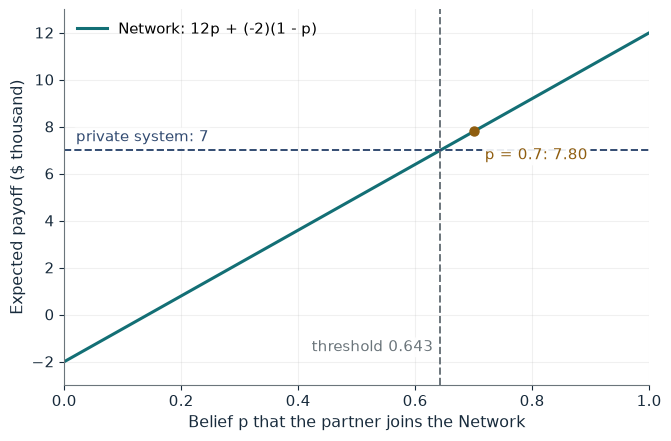

Network payoff    7.80
Private payoff    7
Threshold belief  0.643
Choice            Network

Worked steps:
  1. 12 x 0.7 = 8.40
  2. -2 x 0.30 = -0.60
  3. Network = 7.80 against 7
  4. Threshold = 9 / 14 = 0.643

Without a guarantee, Network pays 12 x 0.7 + (-2) x 0.30 = 8.40 + (-0.60) = 7.80 against 7, so the producer chooses: Network. Network pays off once p reaches (7 - (-2)) / (12 - (-2)) = 0.643.


In [2]:
show(stag_picture(lone=-2, p=0.7))

Change one input, `p`, and hold the others at the book's values:

In [3]:
sweep(stag_picture, 'p', [0.55, 0.6, 0.7], {'lone': 0}, ['Network payoff', 'Threshold belief', 'Choice'])

p | Network payoff | Threshold belief | Choice
0.55 | 6.60 | 0.583 | private system
0.6 | 7.20 | 0.583 | Network
0.7 | 8.40 | 0.583 | Network


Without a guarantee Network needs a belief of 0.643; at 0.70 it pays 7.8. The guarantee lowers the threshold to 0.583, so a belief of 0.60 now gives 7.2 > 7.

## 2. Evolutionarily stable strategy: hawks and doves

$$U_H=x(-20)+(1-x)60=60-80x, \qquad U_D=(1-x)30=30-30x, \qquad U_H-U_D=30-50x$$

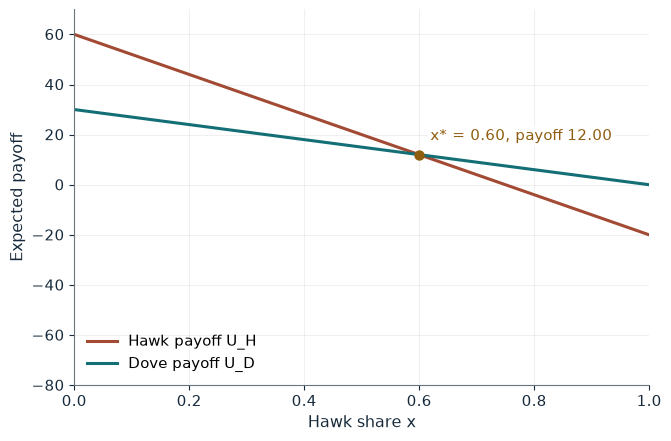

Hawk vs Hawk payoff   -20.0
Stable Hawk share x*  0.60
Payoff at x*          12.00
Type                  mixed

Worked steps:
  1. Hawk vs Hawk = (60 - 100) / 2 = -20.0
  2. x* = 60 / 100 = 0.60
  3. Payoff at x* = (1 - 0.60) x 30 = 12.00

Hawk meeting Hawk gets (60 - 100) / 2 = -20.0. U_H = x(-20.0) + (1 - x)60 and U_D = (1 - x)30 are equal at x* = 60 / 100 = 0.60, where both earn 12.00. At 0.55 Hawk earns 16.00 against 13.50, so Hawks spread; at 0.65 Hawk earns 8.00 against 10.50, so they shrink.


In [4]:
show(hawk_picture(value=60, cost=100))

Change one input, `cost`, and hold the others at the book's values:

In [5]:
sweep(hawk_picture, 'cost', [50, 80, 100, 150], {'value': 60}, ['Stable Hawk share x*', 'Payoff at x*', 'Type'])

cost | Stable Hawk share x* | Payoff at x* | Type
50 | 1.00 | 5.00 | pure Hawk
80 | 0.75 | 7.50 | mixed
100 | 0.60 | 12.00 | mixed
150 | 0.40 | 18.00 | mixed


With V = 60 and C = 100 the stable Hawk share is 0.60 and both types earn 12. At C = 50 Hawk dominates.

## 3. Braess paradox

$$\frac{2{,}000}{100}+45=65\text{ minutes}, \qquad \frac{4{,}000}{100}+\frac{4{,}000}{100}=80$$

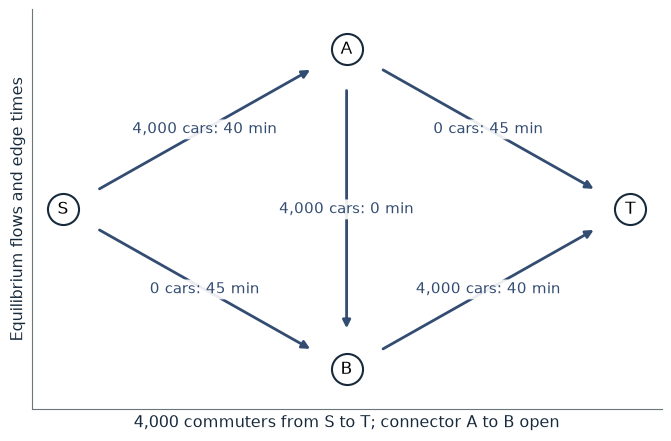

Minutes per commuter          80
Total commuter-minutes        320,000
Minutes with no connector     65
Change from opening the link  +60,000

Worked steps:
  1. No connector: 2,000 / 100 + 45 = 65 minutes
  2. Total with no connector: 4,000 x 65 = 260,000
  3. Connector: 40 + 40 = 80 minutes
  4. Lone switch: 40 + 45 = 85 minutes
  5. Change: 320,000 - 260,000 = 60,000

With the connector everyone takes S, A, B, T: 4,000 / 100 + 4,000 / 100 = 80 minutes, while a lone switch to an old route would take 85. Total 4,000 x 80 = 320,000 against 260,000 without it, so the link hurts everyone.


In [6]:
show(braess_picture(n=4000, link='open'))

Change one input, `n`, and hold the others at the book's values:

In [7]:
sweep(braess_picture, 'n', [2000, 3000, 4000], {'link': 'open'}, ['Minutes per commuter', 'Minutes with no connector', 'Change from opening the link'])

n | Minutes per commuter | Minutes with no connector | Change from opening the link
2000 | 40 | 55 | -30,000
3000 | 60 | 60 | 0
4000 | 80 | 65 | +60,000


With 4,000 commuters the free connector raises everyone's time from 65 to 80 minutes, 60,000 extra commuter-minutes. At 3,000 it makes no difference, and at 2,000 it helps.

## 4. Price of anarchy

$$C(x)=x^2+(1-x), \qquad C'(x)=2x-1, \qquad \operatorname{PoA}=\frac{1}{3/4}=\frac{4}{3}\approx1.333$$

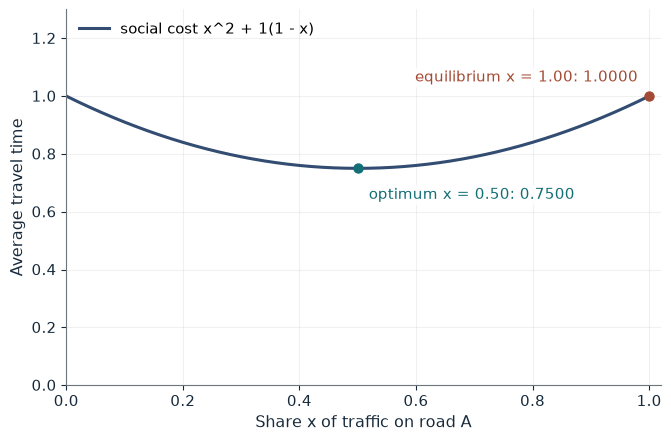

Equilibrium cost    1.0000
Optimal share on A  0.50
Optimal cost        0.7500
Price of anarchy    1.333

Worked steps:
  1. Equilibrium cost = 1.0000
  2. Optimum x = min(1 / 2, 1) = 0.50
  3. Optimal cost = 0.2500 + 0.5000 = 0.7500
  4. PoA = 1.0000 / 0.7500 = 1.333

In equilibrium all traffic uses A, whose latency 1 is at most 1, so cost is 1. The planner sets 2x - 1 = 0, so x = 0.50, with cost 0.50^2 + 1 x 0.50 = 0.2500 + 0.5000 = 0.7500. PoA = 1.0000 / 0.7500 = 1.333.


In [8]:
show(poa_picture(b=1))

Change one input, `b`, and hold the others at the book's values:

In [9]:
sweep(poa_picture, 'b', [0.5, 1, 1.5, 2], {}, ['Equilibrium cost', 'Optimal cost', 'Price of anarchy'])

b | Equilibrium cost | Optimal cost | Price of anarchy
0.5 | 0.5000 | 0.4375 | 1.143
1 | 1.0000 | 0.7500 | 1.333
1.5 | 1.0000 | 0.9375 | 1.067
2 | 1.0000 | 1.0000 | 1.000


With road B at 1 selfish routing costs 4/3 of the optimum. At b = 2 the equilibrium is already optimal.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

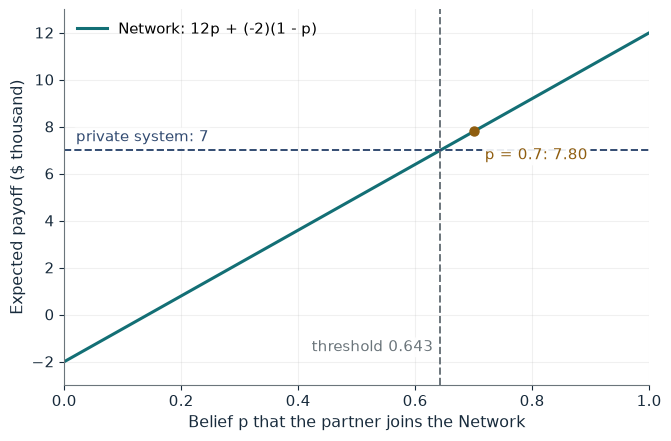

Network payoff    7.80
Private payoff    7
Threshold belief  0.643
Choice            Network

Worked steps:
  1. 12 x 0.7 = 8.40
  2. -2 x 0.30 = -0.60
  3. Network = 7.80 against 7
  4. Threshold = 9 / 14 = 0.643

Without a guarantee, Network pays 12 x 0.7 + (-2) x 0.30 = 8.40 + (-0.60) = 7.80 against 7, so the producer chooses: Network. Network pays off once p reaches (7 - (-2)) / (12 - (-2)) = 0.643.


In [10]:
show(stag_picture(lone=-2, p=0.7))

## Practice

**1.** With the guarantee and p = 0.55, is Network chosen?

<details><summary>Answer</summary>

12 x 0.55 = 6.6 < 7, so no.

</details>

**2.** With V = 60 and C = 150, what is the stable Hawk share?

<details><summary>Answer</summary>

x* = 60 / 150 = 0.40.

</details>

**3.** With road B at 0.5, what is the price of anarchy?

<details><summary>Answer</summary>

0.5 / 0.4375 = 1.143.

</details>